In [45]:
import math
pi = math.pi
import matplotlib.pyplot as plt
import numpy as np
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib
# Integration
import scipy.integrate as integrate
from matplotlib.colors import ListedColormap

In [46]:
from matplotlib.ticker import AutoMinorLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
matplotlib.rcParams.update({'text.usetex': True})
plt.rcParams.update({
       "text.usetex": True,
       "font.family": "serif",
       "font.size": 16,
       "axes.labelsize": 16,
       "axes.titlesize": 16,
       "legend.fontsize": 14,
       "xtick.labelsize": 14,
       "ytick.labelsize": 14,
})
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amssymb}'

### Quantum Dots' Parametrs

$ɛ = 1$ On-site mean local energy

$ɛ_L = ɛ + \frac{1}{2}δ$ On-site mean left energy

$ɛ_R = ɛ - \frac{1}{2}δ$ On-site mean right energy

$δ = 0.0$ detuning

$g =0.5$ coupling strength

$Δ=\sqrt{δ^2+g^2}$

$\Gamma = 0.02 Δ$ coupling to the reservoirs (the overall frequency scale of the dissipative dynamics)

$Ω=10$ Intra-reservoir tunnelling energy/hopping amplitude


In [3]:
# Quantum Dots' Parametrs
eps = 1.0 # on-site mean local energy
delta = 0.0
eps_L = eps + 0.5 * delta
eps_R = eps - 0.5 * delta
g = 0.5 # coupling strength
Delta  = np.sqrt(delta**2 + g**2)
Gamma = 2e-2 * Delta # the overall frequency scale of the dissipative dynamics
Omega = 10.0 # intra-reservoir tunnelling energy/hopping amplitude

### Basis Energies

$E_1 = ɛ+ \frac{Δ}{2}$

$E_1 = ɛ- \frac{Δ}{2}$

In [4]:
# Basis Energies
E1 = eps + 0.5*Delta
E2 = eps - 0.5*Delta

### Reservoirs' parameters


$T=0.3 \varepsilon$

$\mu_L = \varepsilon_L+\varepsilon_R$ Electrochemical potential of the left reservoir

$\mu_R = 0.0$ Electrochemical potential of the right reservoir

In [6]:
# Reservoirs' parameters
T = 0.3 * eps
muL = np.linspace(0.0, (eps_R+eps_L), 301)
muR = np.zeros_like(muL)

### Fermi-Dirac fucntion

\begin{equation*}
f(\omega) = \frac{1}{e^{β(\omega-\mu)}+1}
\end{equation*}


In [7]:
# Dimensionless Fermi-Dirac fucntion expressed with reduced variable x=beta*(E-mu)
f = lambda x: 1./(1. + np.exp(x))

### Spectral density

\begin{align*}
\mathcal{J}_N(\omega) = \frac{\Gamma}{2\pi} \sqrt{1 - \frac{\omega^2}{\Omega^2}} \, \Theta(\Omega - |\omega|)
\end{align*}
### Propability Destribution of Excitation Energy

\begin{align*}
\varphi_j(\omega)=\frac{1}{1-\Gamma / \Omega} \frac{\mathcal{J}_{\mathrm{N}}(\omega)}{\left(\omega-E_j^{\prime}\right)^2+\Gamma_j^2 / 4}
\end{align*}
### Shifted Energies and Decay Rates

\begin{align*}
E'_j = \frac{1 - \Gamma / 2\Omega}{1 - \Gamma / \Omega} E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma.
\end{align*}
### Transmission function

\begin{align*}
\mathcal{T}(\omega)=\frac{\pi g^2}{2} \varphi_1(\omega) \varphi_2(\omega)
\end{align*}

### Uder Exponential-propagator approximation (EPA)

\begin{align*}
E'_j \approx E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma  \approx 2 \pi \mathcal{J}_N(E_j).
\end{align*}

In [8]:
# Spectral density
def J(omega, Gamma, Omega):
     return Gamma/(2.0*np.pi)*np.sqrt(1.0-omega**2/Omega**2)*np.heaviside(Omega-abs(omega),0)
#  Probability distribution of excitation energy
def phi(omega, Gamma, Omega, E):
    E_dash = E
    Gamma_dash = 2.0*np.pi*J(E_dash, Gamma, Omega)
    return 1.0/((omega-E_dash)**2+(Gamma_dash/2.0)**2)*J(omega, Gamma, Omega)
# Trasnmission function
def Tau(omega, Gamma, Omega, E1, E2, g):
    return np.pi*g**2/2.0*phi(omega, Gamma, Omega, E1)*phi(omega, Gamma, Omega, E2)
# Gamma j
Gamma_function = lambda Gamma, Omega, E: (2.0*np.pi*J(E, Gamma, Omega))
# Current
def dI(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))
#Noise
def dS(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)+f((omega-muR)/T)-2.0*f((omega-muL)/T)*f((omega-muR)/T)-Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))**2)

### Average Steady-State Current

\begin{equation*}
    J_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)] d\omega
\end{equation*}

In [9]:
# Integration: <J>
I_avg = np.zeros(np.size(muL)) 
for i in range(np.size(muL)): 
  I_avg[i] = integrate.quad(dI,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T, muL[i], muR[i]), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

### Current Fluctuations

\begin{equation*}
    D_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega) \{ [f_L(\omega)+f_R(\omega)-2f_L(\omega)f_R(\omega)]-\mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)]^2\}
    d\omega
\end{equation*}

In [10]:
# Integration: <<J^2>>
I_I = np.zeros(np.size(muL))
for i in range(np.size(muL)): 
   I_I[i] = integrate.quad(dS,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T, muL[i], muR[i]), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

In [11]:
# Integration: <J>
I_R = np.zeros(np.size(muL)) 
for i in range(np.size(muL)): 
  I_R[i] = integrate.quad(dI,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T, muR[i],muL[i]), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

In [12]:
# Integration: <<J^2>>
I_I_R = np.zeros(np.size(muL))
for i in range(np.size(muL)): 
   I_I_R[i] = integrate.quad(dS,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T, muR[i], muL[i]), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

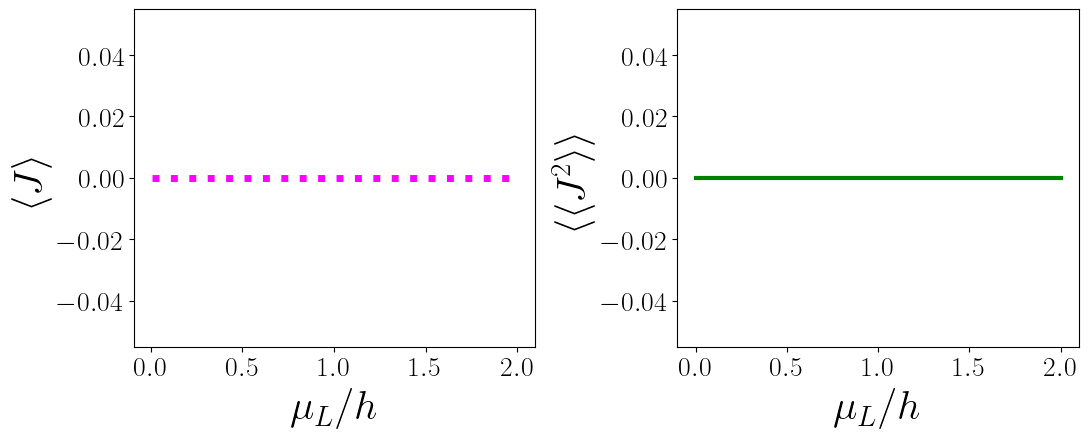

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

l0 = ax[0].plot(muL, (I_avg+I_R)/I_avg,linewidth=5.0, color='magenta',linestyle=':',label=r'$\langle J\rangle_L + \langle J\rangle_R$') #I_2

l1 = ax[1].plot(muL,(I_I-I_I_R)/I_I,linewidth=3.0, color='g',linestyle='-', label=r'$\langle \langle J^2\rangle \rangle_L - \langle \langle J^2\rangle \rangle_R$')

for a in ax.flat:
    a.set(xlabel=r'$\mu_L/h$');
    a.tick_params(labelsize=20);
    a.xaxis.label.set_size(30);
    a.yaxis.label.set_size(30);
    a.set_xticks(np.arange(0, 2.1, 0.5));

ax[0].set(ylabel=r'$\langle J \rangle$');
ax[1].set(ylabel=r'$\langle \langle J^2 \rangle \rangle$');

# ax[0].text(0.1, 1e-1, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
# ax[1].text(0.1, 1e-1, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);

In [14]:
# is it zero within tolerance?
np.where(np.isclose(I_avg, -I_R, rtol=1e-16, atol=0.0) == False)

(array([], dtype=int64),)

In [15]:
np.where(np.isclose(I_I, I_I_R, rtol=1e-16, atol=0.0) == False)

(array([], dtype=int64),)

### Master Eqaution

In [16]:
# #Functions for Current, Flcutuations
def Vectorize_Mat (M):
    return Qobj(np.concatenate([M[:, i:i+1] for i in range(M.shape[1])], axis=0))
#Inputs: LList: list of jump operators; NuList: list of jump coefficients (e.g. +1 and -1 for particle current jumps)
def JJ(LList, NuList):
    result = Qobj(np.zeros(tensor([LList[0].conj(), LList[0]]).shape))
    for i in range(len(NuList)):
        result +=  NuList[i]*Qobj(tensor([LList[i].conj(), LList[i]]),dims=tensor([LList[0].conj(), LList[0]]).shape)
    return result
#Inputs: sst: steady state as qutip object; JJj: Jump operators from above
def Current(sst,JJj):
    N_sst=sst.shape[0]
    id = Vectorize_Mat(qeye(N_sst))
    return(np.real(id.dag()*JJj*Vectorize_Mat(sst)))
##Inputs: Lbb: Lindbladian in qutip format; steadys: steady state in qutip format
# JJ2: the jump operator with all elements in NuList equal to 1; JJ: the jump operator
def Noise(Lbb, steadys, JJ2, JJ):
    N_sst=steadys.shape[0]
    vectsteady=Vectorize_Mat(steadys)
    I2L = Vectorize_Mat(qeye(N_sst)).dag()
    # Calculate the expression using NumPy operations
    alpha=JJ*vectsteady
    A=np.vstack((Lbb.full(),I2L.full()))
    B=np.vstack(((alpha - vectsteady*I2L*alpha).full(),0))
    z= Qobj(np.linalg.lstsq(A,B,rcond=None)[0])
    K=I2L*JJ2*vectsteady
    result = K-2*I2L*JJ*z
    return np.real(result)

In [17]:
from qutip import *
# Creation and annihilation operators for N quantum dots: Define operators for each quantum dot
N = 2
def fermion_annihilation(N, i):
    """
    Fermionic annihilation operator at site i using Jordan-Wigner transformation.

    Parameters:
    - N: total number of sites
    - i: site index (0-based)

    Returns:
    - Qobj: fermionic annihilation operator c_i
    """
    if not (0 <= i < N):
        raise ValueError("Index i must be between 0 and N-1")

    op_list = [sigmaz() for _ in range(i)]          # σ_z^⊗i
    op_list.append(sigmam())                        # σ_-
    op_list.extend([qeye(2) for _ in range(N - i - 1)])  # I^⊗(N-i-1)

    return tensor(op_list)

c0 = fermion_annihilation(N, 0)
c1 = fermion_annihilation(N, 1)

### Non-additivity in the local basis

### Orthogonal Rotation Matrix

\begin{equation*}
R = \frac{1}{\sqrt{2\Delta}}
\left(
\begin{array}{cc}
\sqrt{\Delta + \delta} & -\sqrt{\Delta - \delta} \\ \sqrt{\Delta - \delta} & \sqrt{\Delta + \delta}
\end{array}
\right)
\end{equation*}

In [18]:
# Orthogonal rotation matrix
R = 1.0/np.sqrt(2 * Delta) * np.array([[np.sqrt(Delta+delta), -np.sqrt(Delta-delta)],[np.sqrt(Delta-delta), np.sqrt(Delta+delta)]])

### Decay Rates

\begin{align*}
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma \approx 2 \pi \mathcal{J}_N(E_j)
\end{align*}

### Gammas
$ \Gamma_{L,j}= \Gamma_{j}R_{1j}^2$

$ \Gamma_{R,j}= \Gamma_{j}R_{2j}^2$

$j=1,2$

In [19]:
# Gamma_L,1
GammaL1 = Gamma_function(Gamma, Omega, E1) * R[0,0]**2
# Gamma_L,2
GammaL2 = Gamma_function(Gamma, Omega, E2) * R[0,1]**2
# Gamma_R,1
GammaR1 = Gamma_function(Gamma, Omega, E1) * R[1,0]**2
# Gamma_R,1
GammaR2 = Gamma_function(Gamma, Omega, E2) * R[1,1]**2

In [20]:
# Decay and gain rates
def dg_m(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * (1.0 - f((omega-mu)/T))
def dg_p(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * f((omega-mu)/T)

### Deacay and Gian Rates

\begin{align*}
\gamma_{\alpha, j}^{-}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)[1-f_{α}(ω)] \\
\gamma_{\alpha, j}^{+}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)f_{α}(ω) \\
\end{align*}




In [21]:
# Decay and gain rates
gammaL1_m, gammaR1_m, gammaL2_m, gammaR2_m = np.zeros(np.size(muL)), np.zeros_like(muR), np.zeros_like(muL),np.zeros_like(muR)
gammaL1_p, gammaR1_p, gammaL2_p, gammaR2_p = np.zeros_like(muL), np.zeros_like(muR), np.zeros_like(muL),np.zeros_like(muR)
for i in range(np.size(muL)): 
  gammaL1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1, muL[i], T), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1, muR[i], T), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2, muL[i], T), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2, muR[i], T), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]

  gammaL1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1, muL[i], T), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1, muR[i], T), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2, muL[i], T), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2, muR[i], T), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]

In [22]:
gammaL1_m *= GammaL1
gammaR1_m *= GammaR1
gammaL2_m *= GammaL2
gammaR2_m *= GammaR2

gammaL1_p *= GammaL1
gammaR1_p *= GammaR1
gammaL2_p *= GammaL2
gammaR2_p *= GammaR2

### Non-additive Rates
$\overline{γ}^{\pm}_{\alpha} = {γ}^{\pm}_{1,\alpha} + {γ}^{\pm}_{2,\alpha}$


In [23]:
# Dash rates
gammaL_m_dash = (gammaL1_m + gammaL2_m)
gammaR_m_dash = (gammaR1_m + gammaR2_m)
gammaL_p_dash = (gammaL1_p + gammaL2_p)
gammaR_p_dash = (gammaR1_p + gammaR2_p)

### Delocalised Lindblad Dissipators

\begin{equation*}
\bar{\mathcal{L}}_{LR} \hat{\rho}_S = \sum_{\alpha \neq \alpha'} \left[ \bar{\Lambda}_{\alpha \alpha'}^+ \left( \hat{c}_{\alpha'}^\dagger  \hat{\rho}_S \hat{c}_\alpha - \frac{1}{2} \{ \hat{c}_\alpha \hat{c}_{\alpha'}^\dagger, \hat{\rho }_S \} \right) + \bar{\Lambda}_{\alpha \alpha'}^- \left( \hat{c}_{\alpha} \hat{\rho }_S \hat{c}_{\alpha'}^\dagger - \frac{1}{2} \{ \hat{c}_{\alpha'}^\dagger \hat{c}_\alpha, \hat{\rho }_S \} \right) \right]
\end{equation*}

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [24]:
# Lamda LR PM matrix: Re and Im parts
def dLambda_dash_p_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)+f((omega-muR)/T))
def dLambda_dash_p_im(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))
def dLambda_dash_m_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(2.0 - f((omega-muL)/T)-f((omega-muR)/T))

### Re and Im Parts

\begin{align*}
\text{Re} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ f_L(\omega) + f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{2\Delta} \int d\omega \left[ (E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega) \right] \left[ f_L(\omega) - f_R(\omega) \right], \\
\text{Re} [\bar{\Lambda}^{-}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ 2 - f_L(\omega) - f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{-}_{LR}] &= -\text{Im} [\bar{\Lambda}^{+}_{LR}].
\end{align*}

In [25]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re, Lambda_dash_p_im, Lambda_dash_m_re, Lambda_dash_m_im = np.zeros(np.size(muL)), np.zeros(np.size(muL)), np.zeros(np.size(muL)),np.zeros(np.size(muL))
for i in range(np.size(muL)):
  Lambda_dash_p_re[i] = integrate.quad(dLambda_dash_p_re,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL[i], muR[i], T), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_p_im[i] = integrate.quad(dLambda_dash_p_im,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL[i], muR[i], T), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_m_re[i] = integrate.quad(dLambda_dash_m_re,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL[i], muR[i], T), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]

In [26]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re *= g/(4*Delta)
Lambda_dash_p_im *= g/(2*Delta)
Lambda_dash_m_re *= g/(4*Delta)
Lambda_dash_m_im = - Lambda_dash_p_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}= \mathrm{Re}~ {\bar{\Lambda}}_{LR}^{\pm} + \mathrm{i}~ \mathrm{Im}~ {\bar{\Lambda}}_{LR}^{\pm}
\end{equation*}

In [27]:
# Lamda LR PM matrix:
Lambda_dash_p_LR = Lambda_dash_p_re + 1j * Lambda_dash_p_im
Lambda_dash_m_LR = Lambda_dash_m_re + 1j * Lambda_dash_m_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [28]:
# Lamda RL PM matrix:
Lambda_dash_p_RL = Lambda_dash_p_LR.conjugate()
Lambda_dash_m_RL = Lambda_dash_m_LR.conjugate()

###  Total number operator

$\hat{N} = \hat{n}_L+\hat{n}_R$

In [29]:
# Total number operator
N_hat = c1.dag() * c1 + c0.dag() * c0
n_L = c0.dag() * c0

### Local dissipators are Lindblad generators that act only on a single site
$\bar{\mathcal{L}}_\alpha = \bar{\gamma}_\alpha^- \mathcal{D}[\hat{c}_\alpha] + \bar{\gamma}_\alpha^+ \mathcal{D}[\hat{c}_\alpha^\dagger],$
### Average Steady State Current and its Fluctuations

In [30]:
tau = np.logspace(-8, 3, 331) # Time scale for CP test: Delta t in [1e-8, 1e3]
# tau = np.logspace(2, 5, 331) 
# ======================================================================
# PART 1: allocate arrays (put in the cell BEFORE the loop in cell 49,
#         or at the top of cell 49 / cell 61)
# ======================================================================
choi_min_l = np.zeros((np.size(muL), np.size(tau)))   # min Choi eigenvalue, model (a)
choi_min_g = np.zeros((np.size(muL), np.size(tau)))   # min Choi eigenvalue, model (b)
herm_def_l = np.zeros((np.size(muL), np.size(tau)))   # max |C - C^dagger|, model (a)
herm_def_g = np.zeros((np.size(muL), np.size(tau)))   # max |C - C^dagger|, model (b)

def choi_diagnostics(M):
    """Smallest Choi eigenvalue and Hermiticity defect of a QuTiP map M."""
    C = to_choi(M).full()
    defect = np.max(np.abs(C - C.conj().T))
    lam_min = np.linalg.eigvalsh(0.5 * (C + C.conj().T))[0]   # ascending order
    return lam_min, defect

# ======================================================================
# NEW: tests of the TOTAL map e^{L dt} (unconditional dynamics) and of the generators
# ======================================================================
from scipy.linalg import null_space
choi_min_tot_l = np.zeros((np.size(muL), np.size(tau)))   # min Choi eigenvalue of e^{L t}, c basis
choi_min_tot_g = np.zeros((np.size(muL), np.size(tau)))   # min Choi eigenvalue of e^{L t}, d basis
istp_tot_l = np.zeros((np.size(muL), np.size(tau)), dtype=bool)   # trace preservation of e^{L t}
istp_tot_g = np.zeros((np.size(muL), np.size(tau)), dtype=bool)
lam_L_l, lam_K_l = np.zeros(np.size(muL)), np.zeros(np.size(muL))  # lambda_CCP of L and of the no-jump generator, c basis
lam_L_g, lam_K_g = np.zeros(np.size(muL)), np.zeros(np.size(muL))  # same, d basis

_dim = 4                                              # Hilbert-space dimension of the two-site system
_phi = np.eye(_dim).reshape(-1) / np.sqrt(_dim)       # normalised maximally entangled vector |Phi>
_V = null_space(_phi[None, :])                        # orthonormal basis of the complement of |Phi>

def lam_ccp(Lsup):
    """Smallest eigenvalue of the (unnormalised, QuTiP) Choi matrix of a generator, restricted to the
    complement of |Phi>. lam_ccp >= 0 (up to rounding)  <=>  conditionally CP  <=>  e^{L t} is CP for all t >= 0."""
    C = to_choi(Lsup).full()
    A = _V.conj().T @ C @ _V
    return np.linalg.eigvalsh(0.5 * (A + A.conj().T))[0]

In [31]:
# Current Noise for Attive and Non-Additive Lindblad Master Equation
I_2, I_a, D_a = np.zeros(np.size(muL)), np.zeros(np.size(muL)), np.zeros(np.size(muL))
I_n, D_n = np.zeros(np.size(muL)), np.zeros(np.size(muL))
# Complete Positivity Test
iscp_test_l = np.zeros((np.size(muL),np.size(tau)), dtype=bool)
# On-site energies
H_sys = eps_L * c0.dag()*c0 + eps_R * c1.dag()*c1 - 0.5 * g * (c0.dag() * c1 + c1.dag() * c0)
for i in range(np.size(muL)):
#Non-Lindblad dissipator: general part+anticommutatating term
  D_notLinblad = 0.0
  #LR +
  ad_b = c0 * c1.dag()
  D_notLinblad1 = (spre(c1.dag()) * spost(c0) - 0.5 * spre(ad_b) - 0.5 * spost(ad_b))
  #LR -
  cd_d = c1.dag() * c0
  D_notLinblad2 = (spre(c0) * spost(c1.dag()) - 0.5 * spre(cd_d) - 0.5 * spost(cd_d))
  #RL +
  ed_f = c1 * c0.dag()
  D_notLinblad3 = (spre(c0.dag()) * spost(c1) - 0.5 * spre(ed_f)  - 0.5 * spost(ed_f))
  #RL -
  gd_f = c0.dag()*c1
  D_notLinblad4 = (spre(c1) *spost(c0.dag()) - 0.5 * spre(gd_f) - 0.5 * spost(gd_f))
  D_notLinblad = Lambda_dash_p_LR[i] * D_notLinblad1 + Lambda_dash_m_LR[i] * D_notLinblad2 + Lambda_dash_p_RL[i] * D_notLinblad3 + Lambda_dash_m_RL[i] * D_notLinblad4
  # Left Lindblad part: Colapsed operators
  DL_m = np.sqrt(gammaL_m_dash[i]) * c0
  DL_p = np.sqrt(gammaL_p_dash[i]) * c0.dag()
  # Right Lindblad part: Colapsed operators
  DR_m = np.sqrt(gammaR_m_dash[i]) * c1
  DR_p = np.sqrt(gammaR_p_dash[i]) * c1.dag()

  # Lindblad Liouvillian
  D_Lindblad = liouvillian(H_sys, [DL_m, DL_p, DR_m, DR_p])
  # Full Liouvillian (Non-Lindblad + small Lindblad)
  L_total = D_Lindblad + D_notLinblad
  L_L = lindblad_dissipator(DL_p) + lindblad_dissipator(DL_m)
  L_R = lindblad_dissipator(DR_p) + lindblad_dissipator(DR_m)
  L_I = L_L + D_notLinblad + L_R # Total asymptotic dissipator
  # Find the steady state
  rho_ss_l = steadystate(L_total, method='direct', return_info=True) 
  vector_rho_ss = operator_to_vector(rho_ss_l)
  # Additive Steady State
  rho_ss_l_ad = steadystate(D_Lindblad, method='direct',  return_info=True)
  vector_rho_l_ad = operator_to_vector(rho_ss_l_ad)

  I_2[i] = np.real(vector_to_operator(spre(n_L) * (L_I * vector_rho_ss)).tr())
  Jj = JJ([DL_p, DL_m],[1.0,-1.0])
  I_a[i] = Current(rho_ss_l_ad, JJ([DL_p, DL_m],[1,-1]))  
  D_a[i] = Noise(L_total, rho_ss_l_ad, JJ([DL_p, DL_m],[1,1]), Jj) 
  I_n[i] = Current(rho_ss_l, JJ([DL_p, DL_m],[1,-1]))  
  D_n[i] = Noise(L_total, rho_ss_l, JJ([DL_p, DL_m],[1,1]), Jj) 
  
  # No-jump generator and conditional-CP test of the generators (independent of Delta t)
  K_l = L_total - sum(sprepost(L, L.dag()) for L in [DL_m, DL_p, DR_m, DR_p])
  lam_L_l[i], lam_K_l[i] = lam_ccp(L_total), lam_ccp(K_l)

  #Testing Complete positivity
  for j in range(np.size(tau)):
    t = tau[j] # time interval
    M0 = (t * K_l).expm()                       # no-jump map
    choi_min_l[i,j], herm_def_l[i,j] = choi_diagnostics(M0)
    iscp_test_l[i,j] = M0.iscp
    Mt = (t * L_total).expm()                   # NEW: total (unconditional) map
    choi_min_tot_l[i,j], _ = choi_diagnostics(Mt)
    istp_tot_l[i,j] = Mt.istp

In [32]:
print(qutip.__version__)
# QuTiP 5.x
print(qutip.settings.core['atol'], qutip.settings.core['rtol'])

5.2.0
1e-12 1e-12


In [33]:
d = 4
labels = [f"|{nL}{nR}>" for nL in (1, 0) for nR in (1, 0)]   # index -> |n_L n_R>

C = to_choi(M0).full()
choi_state = C / d
print("Tr(Choi state) =", np.trace(choi_state).real)

def lab(idx):
    i, k = divmod(idx, d)
    return f"in {labels[i]} -> out {labels[k]}"

# Show the large entries with labels
for r, c in zip(*np.where(np.abs(C) > 0.05)):
    if r <= c:
        print(f"C[{r},{c}] = {C[r,c]:.3f}   row: {lab(r)} | col: {lab(c)}")

# Get the output operator Λ(|i><j|) directly:
C4 = C.reshape(d, d, d, d)      # indices [i, k, j, l]
Lam_ij = C4[1, :, 2, :]         # Λ(|10><01|) as a 4x4 matrix

Tr(Choi state) = 4.6533080858032655e-05


###  Non-additivity in the energy eigenbasis

$\mathbf{\hat{d}} =R\mathbf{\hat{c}}$  

### Rate Matrices

\begin{equation*}
{\Lambda}_{12}^{+}=({\Lambda}_{21}^{+})^* = \xi + \mathrm{i}\eta
\end{equation*}

\begin{align*}
\xi = \frac{g}{4\Delta} \int \mathrm{d}\omega \sum_{j=1}^{2} \Gamma_j \varphi_j(\omega) [f_L(\omega) - f_R(\omega)], \\
\eta = \frac{g}{2\Delta} \int \mathrm{d}\omega [(E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega)] [f_L(\omega) - f_R(\omega)]
\end{align*}



In [34]:
# Lamda LR PM matrix: Re and Im parts
def d_xi(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)+Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)-f((omega-muR)/T))
def d_eta(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))

In [35]:
# Lamda 12 P matrix: Re and Im parts
xi, eta = np.zeros_like(muL, dtype = float), np.zeros_like(muL, dtype = float)
for i in range(np.size(muL)):
  xi[i] = integrate.quad(d_xi,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL[i], muR[i], T), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-14)[0]
  eta[i] = integrate.quad(d_eta,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL[i], muR[i], T), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-14)[0]

In [36]:
xi *= g/(4*Delta)
eta *= g/(2*Delta)

In [37]:
# Lamda 12 P matrix:
Lambda_p_12 = (xi + 1j*eta)
# Lamda 21 P matrix:
Lambda_p_21 = Lambda_p_12.conjugate()

In [38]:
np.where((gammaL1_p +gammaR1_p)*(gammaL2_p +gammaR2_p)-abs(Lambda_p_21)**2 < 0.0)

(array([], dtype=int64),)

In [39]:
#Lambda_p_12 = - Lambda_m_12
#Lambda_p_21 = - Lambda_m_21
np.where((gammaL1_m +gammaR1_m)*(gammaL2_m +gammaR2_m)-abs(Lambda_p_21)**2 < 0.0)

(array([], dtype=int64),)

### Interference contribution to the dissipator

\begin{align*}
\mathcal{L}_{\text{int}}\hat{\rho}_S =\sum_{j \neq k} \Lambda^+_{jk} \left[ \left(\hat{d}_k^\dagger \hat{\rho}_S \hat{d}_j - \frac{1}{2} \{\hat{d}_j \hat{d}_k^\dagger, \hat{\rho}_S\} \right) - \left(\hat{d}_j \hat{\rho}_S \hat{d}_k^\dagger - \frac{1}{2} \{\hat{d}_k^\dagger \hat{d}_j, \hat{\rho}_S\}\right) \right]
\end{align*}

### Local dissipators are Lindblad generators that act only on a single site
$\mathcal{L}_\alpha = \sum_{j=1}^2 \gamma_{\alpha,j}^- \mathcal{D}[\hat{d}_j] + \gamma_{\alpha,j}^+ \mathcal{D}[\hat{d}_j^\dagger],$
### Average Steady State Current
$J_L = \langle \mathcal{L}^{\dagger} \hat{n}_L \rangle_{\infty} = \langle \mathcal{L}^{\dagger} \hat{N} \rangle_{\infty}$
### Current Fluctuation

In [40]:
#Current Dynamica Activty and Noise for Local Lindblad Equation
I_d, D_ad, D_nd =  np.zeros_like(muL, dtype = float), np.zeros_like(muL, dtype = float), np.zeros_like(muL, dtype = float)
Ia_d, In_d = np.zeros_like(muL, dtype = float), np.zeros_like(muL, dtype = float)
iscp_test_g = np.zeros((np.size(muL),np.size(tau)), dtype=bool)
# On-site energies
d1 = R[0,0] * c0 + R[0,1] * c1
d2 = R[1,0] * c0 + R[1,1] * c1
N_S = d1.dag() * d1 + d2.dag() * d2
H_d = E1 * d1.dag() * d1 + E2 * d2.dag() * d2
n_L_12 = (R.T[0,0])**2 * d1.dag() * d1 + R.T[0,0] * R.T[0,1] * d1.dag() * d2 + R.T[0,1] * R.T[0,0] * d2.dag() * d1 + (R.T[0,1])**2 * d2.dag() * d2
for i in range(np.size(muL)): 
# Non-Lindblad dissipator: general part+anticommutatating term
  D_int_12_p = (sprepost(d2.dag(), d1) - 0.5 * spre(d1 * d2.dag()) - 0.5 * spost(d1 * d2.dag()))
  # 12 -
  D_int_12_m = (sprepost(d1, d2.dag()) - 0.5 * spre(d2.dag() * d1) - 0.5 * spost(d2.dag() * d1))
  # 21 +
  D_int_21_p = (sprepost(d1.dag(), d2) - 0.5 * spre(d2 * d1.dag()) - 0.5 * spost(d2 * d1.dag()))
  # 21 -
  D_int_21_m = (sprepost(d2, d1.dag()) - 0.5 * spre(d1.dag() * d2) - 0.5 * spost(d1.dag() * d2))
  D_int = Lambda_p_12[i] * D_int_12_p - Lambda_p_12[i] * D_int_12_m + Lambda_p_21[i] * D_int_21_p - Lambda_p_21[i] * D_int_21_m
  # Left Lindblad part: Colapsed operators
  DL_1 = np.sqrt(gammaL1_m[i]) * d1 
  DL_2 = np.sqrt(gammaL2_m[i]) * d2 

  DL_1d = np.sqrt(gammaL1_p[i]) * d1.dag()
  DL_2d = np.sqrt(gammaL2_p[i]) * d2.dag()
  # Right Lindblad part: Colapsed operators
  DR_1 = np.sqrt(gammaR1_m[i]) * d1
  DR_2 = np.sqrt(gammaR2_m[i]) * d2

  DR_1d = np.sqrt(gammaR1_p[i]) * d1.dag()
  DR_2d = np.sqrt(gammaR2_p[i]) * d2.dag()
  # Lindblad Liouvillian
  D_Lindblad_g = liouvillian(H_d, [DL_1, DL_2, DL_1d, DL_2d, DR_1, DR_2, DR_1d, DR_2d])
  # Full Liouvillian (Non-Lindblad + small Lindblad)
  L_total_g = D_Lindblad_g + D_int
  L_L_g = lindblad_dissipator(DL_1) + lindblad_dissipator(DL_2) + lindblad_dissipator(DL_1d) + lindblad_dissipator(DL_2d)
  L_R_g = lindblad_dissipator(DR_1) + lindblad_dissipator(DR_2) + lindblad_dissipator(DR_1d) + lindblad_dissipator(DR_2d)
  L_I_g = L_L_g + D_int + L_R_g # Total asymptotic dissipator
  # Find the steady state
  rho_ss_g = steadystate(L_total_g, method='direct', return_info=True) 
  vector_rho_ss = operator_to_vector(rho_ss_g)
  # Additive Steady State
  rho_ss_g_ad = steadystate(D_Lindblad_g, method='direct',  return_info=True)
  vector_rho_ad_g = operator_to_vector(rho_ss_g_ad)
  
  I_d[i] = np.real(vector_to_operator((spre(n_L_12) * (L_I_g * vector_rho_ss))).tr())
  Jj_g = JJ([DL_1d, DL_2d, DL_1, DL_2], [1.0, 1.0, -1.0, -1.0])
  Ia_d[i] = Current(rho_ss_g_ad,Jj_g) 
  In_d[i] = Current(rho_ss_g,Jj_g)
  D_ad[i] =  Noise(L_total_g, rho_ss_g_ad, JJ([DL_1d, DL_2d, DL_1, DL_2],[1.0, 1.0, 1.0, 1.0]), Jj_g)
  D_nd[i] =  Noise(L_total_g, rho_ss_g, JJ([DL_1d, DL_2d, DL_1, DL_2],[1.0, 1.0, 1.0, 1.0]), Jj_g)
  # Effective non-Hermitian Hamiltonian
  H_eff = H_sys - 0.5j * sum(L.dag() * L for L in [DL_1, DL_2, DL_1d, DL_2d, DR_1, DR_2, DR_1d, DR_2d])
  Hat_eff = -1j * (spre(H_eff) - spost(H_eff.dag())) 
  # No-jump generator and conditional-CP test of the generators (independent of Delta t)
  jump_ops_g = [DL_1, DL_2, DL_1d, DL_2d, DR_1, DR_2, DR_1d, DR_2d]
  K_g = L_total_g - sum(sprepost(L, L.dag()) for L in jump_ops_g)
  lam_L_g[i], lam_K_g[i] = lam_ccp(L_total_g), lam_ccp(K_g)
  # Testing Complete positivity
  for j in range(np.size(tau)):
    t = tau[j] # time interval
    Mg0 = (t * K_g).expm()                      # no-jump map
    choi_min_g[i,j], herm_def_g[i,j] = choi_diagnostics(Mg0)
    iscp_test_g[i,j] = Mg0.iscp
    Mgt = (t * L_total_g).expm()                # NEW: total (unconditional) map
    choi_min_tot_g[i,j], _ = choi_diagnostics(Mgt)
    istp_tot_g[i,j] = Mgt.istp


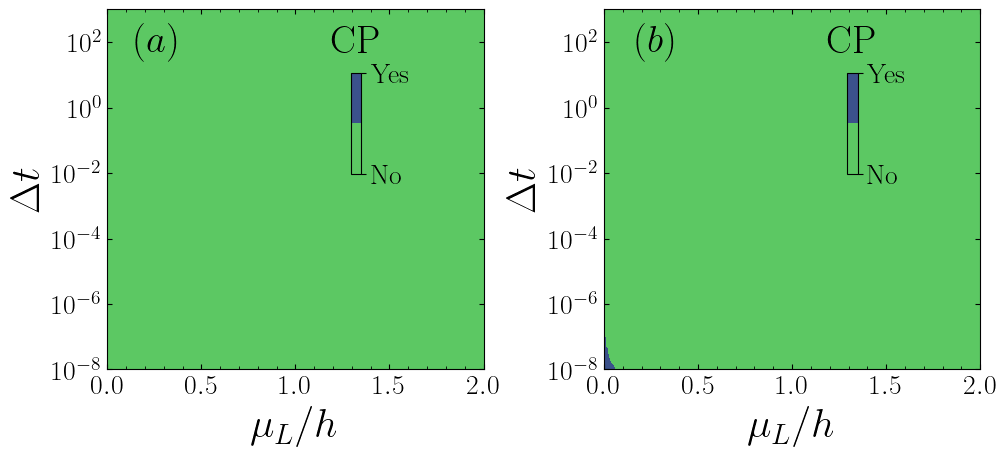

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5)) 

mycmap = matplotlib.colors.LinearSegmentedColormap.from_list("",["seagreen","crimson"])

for a in ax.flat:
    a.tick_params(which='both', direction="in", top=True, bottom=True, left=True, right=True)
    a.xaxis.set_minor_locator(AutoMinorLocator())
    a.yaxis.set_minor_locator(AutoMinorLocator())

#Plot 1
l1 = ax[0].contourf(muL/eps, tau, (iscp_test_l.T), cmap='viridis_r') 
axi = inset_axes(ax[0], width="5%", height="40%", loc='upper right',
                 bbox_to_anchor=(0.15, 0.15, 0.55, 0.7),
                 bbox_transform=ax[0].transAxes, borderpad=0.5)
# cbar1 = fig.colorbar(l1, cax=axi, ticks=[0, 1]) 
cbar1 = fig.colorbar(l1, cax=axi, ticks=[0, 1]) 
cbar1.set_ticklabels(["No", "Yes"]);
cbar1.ax.set_title(r'$\mathrm{CP}$', pad=15, fontsize=28)
cbar1.ax.tick_params(labelsize=20)

# Plot 2
l1 = ax[1].contourf(muL/eps, tau, (iscp_test_g.T), cmap='viridis_r') 
axii = inset_axes(ax[1], width="5%", height="40%", loc='upper right',
                 bbox_to_anchor=(0.15, 0.15, 0.55, 0.7),
                 bbox_transform=ax[1].transAxes, borderpad=0.5)
cbar2 = fig.colorbar(l1, cax=axii, ticks=[0, 1]) 
cbar2.set_ticklabels(["No", "Yes"]);
cbar2.ax.set_title(r'$\mathrm{CP}$', pad=15, fontsize=28)
cbar2.ax.tick_params(labelsize=20)

# Axis labels and ticks
for a in ax.flat:
    a.set_xlabel(r'$\mu_L/h$') 
    a.set_ylabel(r'$\Delta t$') 
    a.tick_params(axis='x') 
    a.tick_params(axis='y') 
    a.set_yscale('log');
    a.tick_params(labelsize=20);
    a.xaxis.label.set_size(30);
    a.yaxis.label.set_size(30);


ax[0].text(0.4, 1e2, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.4, 1e2, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

plt.tight_layout(pad=.3, w_pad=.3, h_pad=.3);
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/maps_CP_both_mu.pdf', format='pdf')

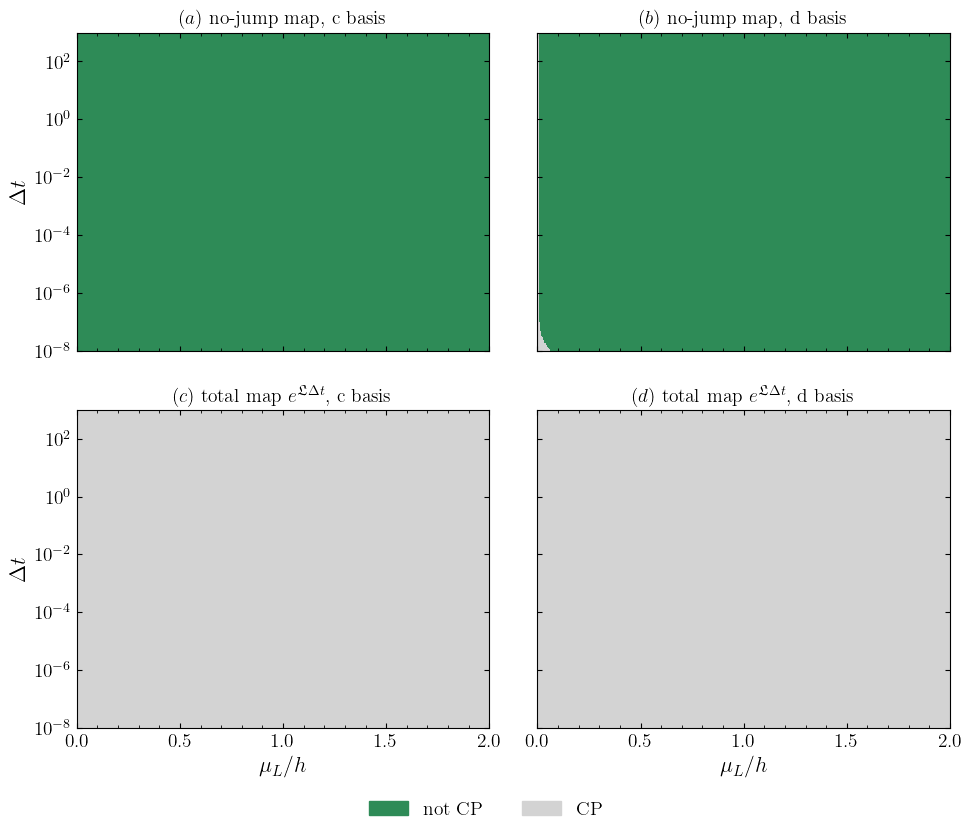

In [47]:
# Fig. 6 extended: top row = no-jump map, bottom row = total (unconditional) map e^{L dt}
atol_cp = 1e-12                     # eigenvalue tolerance for the CP verdict (state it in Table 3)
cmap_cp = matplotlib.colors.ListedColormap(["seagreen", "lightgray"])   # green = not CP, gray = CP
fig, ax = plt.subplots(2, 2, figsize=(10, 8.5), sharex=True, sharey=True)
panels = [(ax[0,0], choi_min_l,     r'$(a)$ no-jump map, c basis'),
          (ax[0,1], choi_min_g,     r'$(b)$ no-jump map, d basis'),
          (ax[1,0], choi_min_tot_l, r'$(c)$ total map $e^{\mathfrak{L}\Delta t}$, c basis'),
          (ax[1,1], choi_min_tot_g, r'$(d)$ total map $e^{\mathfrak{L}\Delta t}$, d basis')]
for a, m, ttl in panels:
    a.contourf(muL/eps, tau, (m >= -atol_cp).astype(float).T, levels=[-0.5, 0.5, 1.5], cmap=cmap_cp)
    a.set_yscale('log'); a.set_title(ttl, fontsize=14)
    a.tick_params(which='both', direction="in", top=True, right=True)
    a.xaxis.set_minor_locator(AutoMinorLocator())
for a in ax[1]: a.set_xlabel(r'$\mu_L/h$')
for a in ax[:,0]: a.set_ylabel(r'$\Delta t$')
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='seagreen', label='not CP'), Patch(color='lightgray', label='CP')],
           loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
#fig.savefig('maps_CP_nojump_vs_total.pdf', format='pdf')

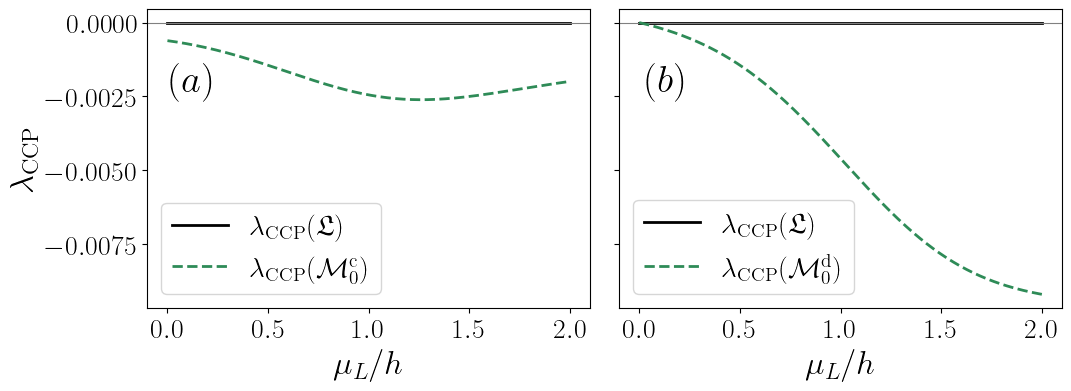

In [48]:
# Tolerance-free criterion: lambda_CCP of the generators (>= 0  <=>  GKSL / conditionally CP)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for a, lL, lK, ttl in [(ax[0], lam_L_l, lam_K_l, r''), (ax[1], lam_L_g, lam_K_g, r'')]:
    a.plot(muL/eps, lL, color='k', lw=2, label=r'$\lambda_{\rm CCP}(\mathfrak{L})$')
    # a.plot(muL/eps, lK, color='seagreen', lw=2, ls='--', label=r'$\lambda_{\rm CCP}(\mathcal{M}_0^{\rm m})$ (no-jump)')
    a.axhline(0, color='gray', lw=0.8)
    a.set_xlabel(r'$\mu_L/h$');
    a.tick_params(labelsize=20); 
    a.xaxis.label.set_size(24);
    a.yaxis.label.set_size(24);
    
ax[0].set_ylabel(r'$\lambda_{\rm CCP}$'); 
ax[0].xaxis.label.set_size(24);
ax[0].plot(muL/eps, lam_K_l, color='seagreen', lw=2, ls='--', label=r'$\lambda_{\rm CCP}(\mathcal{M}_0^{\rm c})$')
ax[1].plot(muL/eps, lam_K_g, color='seagreen', lw=2, ls='--', label=r'$\lambda_{\rm CCP}(\mathcal{M}_0^{\rm d})$')
ax[0].legend(fontsize=20, loc='lower left')
ax[1].legend(fontsize=20, loc='lower left')
plt.tight_layout()
gksl_c = lam_L_l >= -1e-12          # region where L is of GKSL form (c basis); same test for d basis below
gksl_g = lam_L_g >= -1e-12
# print("GKSL region, c basis: mu_L/h =", np.round(muL[gksl_c]/eps, 3))
# print("GKSL region, d basis: mu_L/h =", np.round(muL[gksl_g]/eps, 3))
# Check of the claim "no-jump map is not CP while L is GKSL": no-jump violations at GKSL points
iol_in_gksl = ((choi_min_l < -1e-12) & gksl_c[:, None]).any()

ax[0].text(0.25, -2e-3, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.25, -2e-3, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/eigenvalues_choi_matrix.pdf', format='pdf')

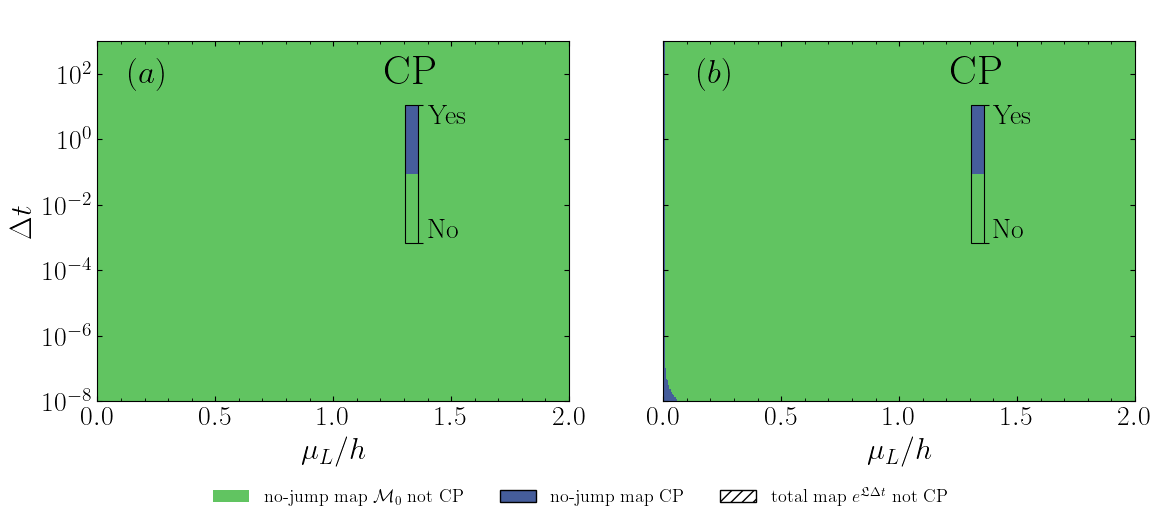

In [49]:
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
atol_cp = 1e-12
cmap_cp = ListedColormap(["#61C461", "#455D9B"])   # green = no-jump map NOT CP, white = CP

def cp_overlay(ax, nj_min, tot_min, lam_L, title, mode='point'):
    X, Y = muL/eps, tau
    l1 = ax.contourf(X, Y, (nj_min >= -atol_cp).astype(float).T, levels=[-0.5, 0.5, 1.5], cmap=cmap_cp)
    if mode == 'point':      # hatch points where the total map e^{L dt} is not CP
        bad = (tot_min < -atol_cp)
    else:                    # hatch whole mu_L columns where L is not GKSL
        bad = np.repeat((lam_L < -atol_cp)[:, None], np.size(tau), axis=1)
    with plt.rc_context({'hatch.color': 'k', 'hatch.linewidth': 0.8}):
        ax.contourf(X, Y, bad.astype(float).T, levels=[0.5, 1.5], colors='none', hatches=['///'])
    ax.contour(X, Y, bad.astype(float).T, levels=[0.5], colors='k', linewidths=1.2)
    ax.set_yscale('log'); ax.set_xlabel(r'$\mu_L/h$'); ax.set_title(title, fontsize=24)
    ax.set_xticks(np.arange(0, 2.1, 0.5));
    ax.xaxis.label.set_size(22);
    ax.yaxis.label.set_size(22);
    ax.tick_params(labelsize=20);
    ax.tick_params(which='both', direction="in", top=True, right=True)
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    return l1                                              # <- needed for the colorbar

def add_cp_cbar(fig, ax, l1, inside=False, fs_title=30, fs_ticks=20):
    if inside:   # your original placement
        cax = inset_axes(ax, width="5%", height="55%", loc='upper right',
                         bbox_to_anchor=(0.15, 0.15, 0.55, 0.7), bbox_transform=ax.transAxes, borderpad=0.5)
    else:        # to the right of the panel
        cax = inset_axes(ax, width="4%", height="55%", loc='center left',
                         bbox_to_anchor=(1.03, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
    cb = fig.colorbar(l1, cax=cax, ticks=[l1.levels[0], l1.levels[-1]])   # ticks at the bottom and top ends
    cb.set_ticklabels(["No", "Yes"])
    for lab, va in zip(cb.ax.get_yticklabels(), ["bottom", "top"]):        # keep the labels inside the bar's extent
        lab.set_va(va)
    cb.ax.set_title(r'$\mathrm{CP}$', pad=15, fontsize=fs_title)
    cb.ax.tick_params(labelsize=fs_ticks)
    return cb


fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True)
l1 = cp_overlay(ax[0], choi_min_l, choi_min_tot_l, lam_L_l, r' ', mode='point')
add_cp_cbar(fig, ax[0], l1, inside=True)
l2 = cp_overlay(ax[1], choi_min_g, choi_min_tot_g, lam_L_g, r' ', mode='point')
add_cp_cbar(fig, ax[1], l2, inside=True)
ax[0].set_ylabel(r'$\Delta t$')
ax[0].text(0.3, 1e2, r"$(a)$",{'color': 'black', 'fontsize': 24}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.3, 1e2, r"$(b)$",{'color': 'black', 'fontsize': 24}, horizontalalignment='right', verticalalignment='center');
# fig.legend(handles=[Patch(facecolor='white', edgecolor='k', hatch='///', label=r'total map $e^{\mathfrak{L}\Delta t}$ not CP')],
#            loc='lower center', frameon=False, fontsize=13)
fig.legend(handles=[Patch(facecolor="#61C461", label=r'no-jump map $\mathcal{M}_0$ not CP'),
                    Patch(facecolor="#455D9B", edgecolor='k', label=r'no-jump map CP'),
                    Patch(facecolor='white', edgecolor='k', hatch='///', label=r'total map $e^{\mathfrak{L}\Delta t}$ not CP')],
           loc='lower center', ncol=3, frameon=False, fontsize=13)
fig.subplots_adjust(left=0.08, right=0.91, bottom=0.25, top=1.0, wspace=0.2, hspace=0.3)
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/maps_CP_nojump_hatched_total.pdf', format='pdf')

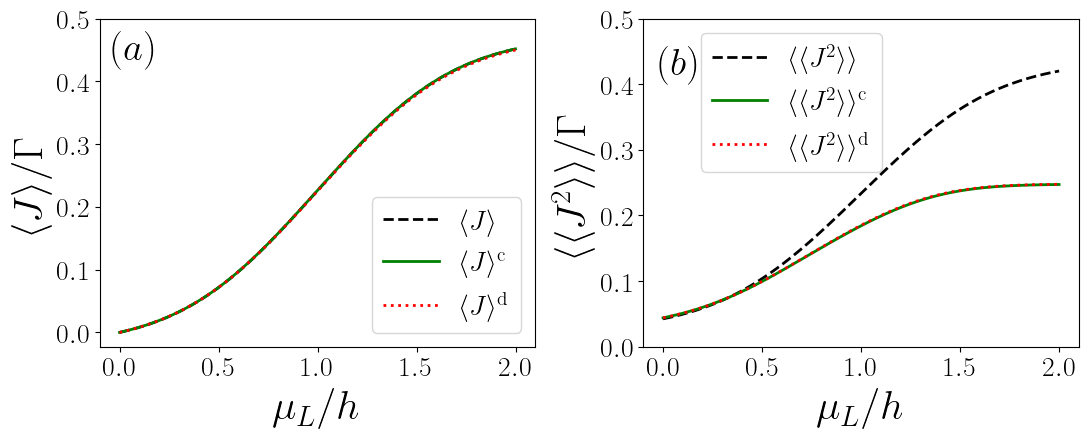

In [50]:
#Plot <J>, <<J^2>> vs. muL
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

l0 = ax[0].plot(muL/eps, I_avg/Gamma,linewidth=2.0, color='black',linestyle='--',label=r'$\langle J \rangle$') 

l0 = ax[0].plot(muL/eps, I_n/Gamma, linewidth=2.0, color='g',linestyle='-',label=r'$\langle J \rangle^{\rm c}$') #_{\rm N} 

l0 = ax[0].plot(muL/eps, In_d/Gamma, linewidth=2.0, color='r',linestyle=':',label=r'$\langle J \rangle^{\rm d}$') #^{\rm N} 

l1 = ax[1].plot(muL/eps,I_I/Gamma,linewidth=2.0, color='black',linestyle='--', label=r'$\langle \langle J^2 \rangle \rangle$')

l2 = ax[1].plot(muL/eps,D_n/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'$\langle \langle J^2 \rangle \rangle^{\rm c}$') #^{\rm N} 

l2 = ax[1].plot(muL/eps,D_nd/Gamma,linewidth=2.0, color='r',linestyle=':', label=r'$\langle \langle J^2 \rangle \rangle^{\rm d}$') #^{\rm N} 

ax[0].text(0.2, 0.45, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.2, 0.43, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

for a in ax.flat:
    a.legend(loc='lower right', fontsize=20);
    a.set(xlabel=r'$\mu_L/h$');
    a.tick_params(labelsize=20);
    a.set_xticks(np.arange(0, 2.1, 0.5));
    a.set_yticks(np.arange(0, 0.51, 0.1));
    a.xaxis.label.set_size(30);
    a.yaxis.label.set_size(30);

ax[0].set(ylabel=r'$\langle J \rangle/\Gamma$');
ax[1].set(ylabel=r'$\langle \langle J^2 \rangle \rangle/\Gamma$');
ax[1].legend(loc='upper center', bbox_to_anchor=(0.34, 1.0), fontsize=20)
plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/current_fluctuations_over_chemical_potential.pdf', format='pdf')

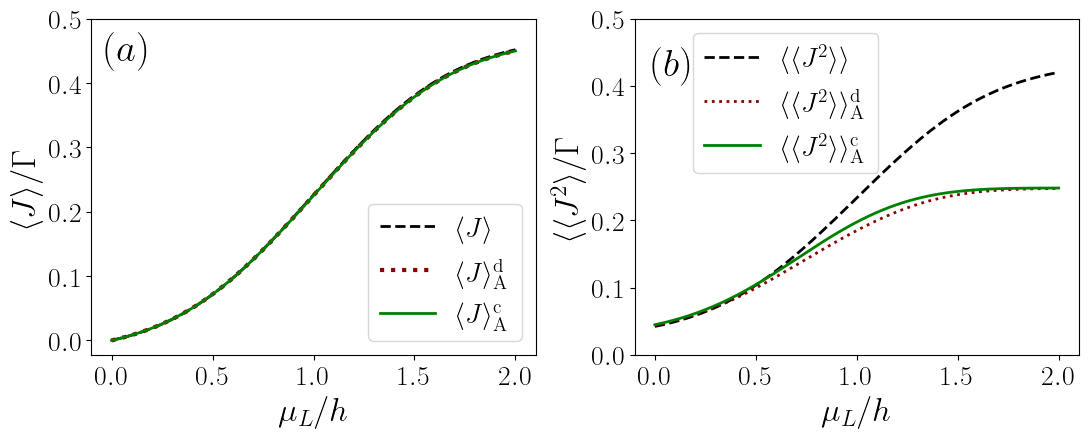

In [51]:
#Plot <J>, <<J^2>> vs. muL
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


l0 = ax[0].plot(muL/eps, I_avg/Gamma,linewidth=2.0, color='black',linestyle='--',label=r'$\langle J \rangle$') 

l1 = ax[1].plot(muL/eps,I_I/Gamma,linewidth=2.0, color='black',linestyle='--', label=r'$\langle \langle J^2 \rangle \rangle$')

l0 = ax[0].plot(muL/eps, (In_d)/Gamma,linewidth=3.0, color='darkred',linestyle=':', label=r'$\langle J \rangle^{\rm d}_{\rm A}$')

l1 = ax[1].plot(muL/eps, (D_ad)/Gamma,linewidth=2.0, color='darkred',linestyle=':', label=r'$\langle \langle J^2 \rangle \rangle^{\rm d}_{\rm A}$')

l2 = ax[0].plot(muL/eps, (I_a)/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'$\langle J \rangle^{\rm c}_{\rm A}$')
l3 = ax[1].plot(muL/eps, (D_a)/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'$\langle \langle J^2 \rangle \rangle^{\rm c}_{\rm A}$')


for a in ax.flat:
    a.legend(loc='lower right', fontsize=20);
    a.set(ylabel=r'$ \Delta \langle \langle J^2 \rangle \rangle/\Gamma$');  
    a.set(xlabel=r'$\mu_L/h$');
    a.tick_params(labelsize=20);
    a.set_xticks(np.arange(0, 2.1, 0.5));
    a.xaxis.label.set_size(24);
    a.yaxis.label.set_size(24);

ax[0].set_yticks(np.arange(0, 0.51, 0.1));
ax[1].set_yticks(np.arange(0, 0.51, 0.1));


ax[0].set(ylabel=r'$\langle J \rangle/\Gamma$');
ax[1].set(ylabel=r'$\langle \langle J^2 \rangle/\Gamma$'); 

ax[0].text(0.2, 0.45, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.2, 0.43, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

ax[1].legend(loc='upper center', bbox_to_anchor=(0.34, 1.0), fontsize=20)

plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);

#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/additive_chemical_potential.pdf', format='pdf')

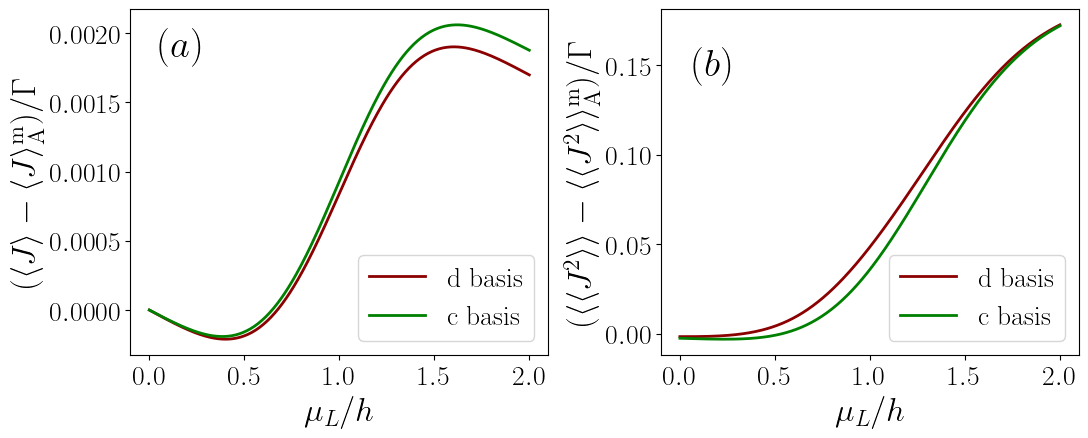

In [52]:
#Plot <J>, <<J^2>> vs. muL
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

l0 = ax[0].plot(muL/eps, (I_avg-In_d)/Gamma,linewidth=2.0, color='darkred',linestyle='-', label=r'${\rm d}~\mathrm{basis}$')

l1 = ax[1].plot(muL/eps, (I_I-D_ad)/Gamma,linewidth=2.0, color='darkred',linestyle='-', label=r'${\rm d}~\mathrm{basis}$')

l2 = ax[0].plot(muL/eps, (I_avg-I_a)/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'${\rm c}~\mathrm{basis}$')
l3 = ax[1].plot(muL/eps, (I_I-D_a)/Gamma,linewidth=2.0, color='g',linestyle='-', label=r'${\rm c}~\mathrm{basis}$')


for a in ax.flat:
    a.legend(loc='lower right', fontsize=20);
    a.set(ylabel=r'$ \Delta \langle \langle J^2 \rangle \rangle/\Gamma$');  
    a.set(xlabel=r'$\mu_L/h$');
    a.tick_params(labelsize=20);
    a.set_xticks(np.arange(0, 2.1, 0.5));
    a.xaxis.label.set_size(24);
    a.yaxis.label.set_size(24);

ax[0].set(ylabel=r'$(\langle J \rangle - \langle J \rangle^{\rm m}_{\rm A})/\Gamma$');
ax[1].set(ylabel=r'$(\langle \langle J^2 \rangle \rangle - \langle \langle J^2 \rangle \rangle^{\rm m}_{\rm A})/\Gamma$'); 
ax[0].text(0.3, 0.0019, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
ax[1].text(0.3, 0.15, r"$(b)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/fom_over_chemical_potential.pdf', format='pdf')

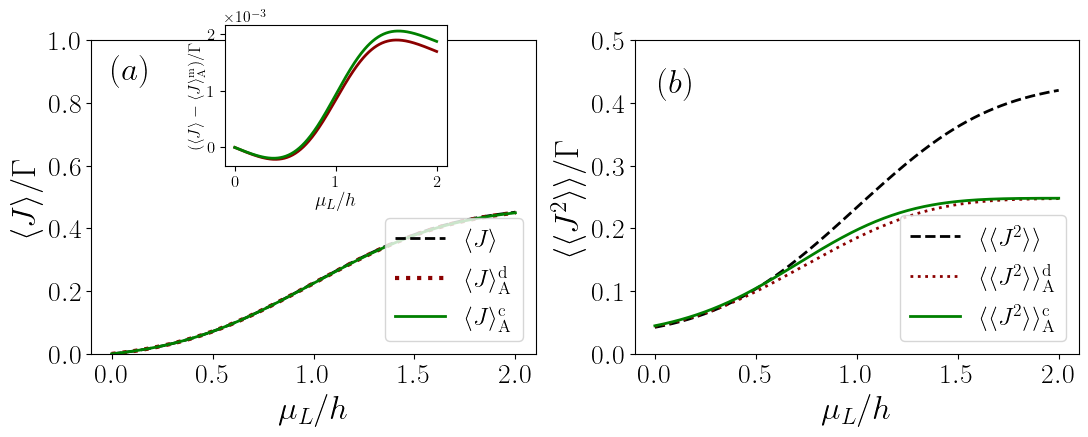

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# ---------------- Panel (a): <J> ----------------
ax[0].plot(muL/eps, I_avg/Gamma, linewidth=2.0, color='black', linestyle='--',
           label=r'$\langle J \rangle$')
ax[0].plot(muL/eps, In_d/Gamma, linewidth=3.0, color='darkred', linestyle=':',
           label=r'$\langle J \rangle^{\rm d}_{\rm A}$')
ax[0].plot(muL/eps, I_a/Gamma, linewidth=2.0, color='g', linestyle='-',
           label=r'$\langle J \rangle^{\rm c}_{\rm A}$')

# ---------------- Panel (b): <<J^2>> ----------------
ax[1].plot(muL/eps, I_I/Gamma, linewidth=2.0, color='black', linestyle='--',
           label=r'$\langle \langle J^2 \rangle \rangle$')
ax[1].plot(muL/eps, D_ad/Gamma, linewidth=2.0, color='darkred', linestyle=':',
           label=r'$\langle \langle J^2 \rangle \rangle^{\rm d}_{\rm A}$')
ax[1].plot(muL/eps, D_a/Gamma, linewidth=2.0, color='g', linestyle='-',
           label=r'$\langle \langle J^2 \rangle \rangle^{\rm c}_{\rm A}$')

# ---------------- Common formatting ----------------
for a in ax.flat:
    a.legend(loc='lower right', fontsize=18)
    a.set_xlabel(r'$\mu_L/h$')
    a.tick_params(labelsize=20)
    a.set_xticks(np.arange(0, 2.1, 0.5))
    a.xaxis.label.set_size(24)
    a.yaxis.label.set_size(24)
    a.set_yticks(np.arange(0, 0.51, 0.1))

ax[0].set_ylabel(r'$\langle J \rangle/\Gamma$')
ax[1].set_ylabel(r'$\langle \langle J^2 \rangle \rangle/\Gamma$')

ax[0].text(0.2, 0.9, r"$(a)$", color='black', fontsize=24,
           ha='right', va='center')
ax[1].text(0.2, 0.43, r"$(b)$", color='black', fontsize=24,
           ha='right', va='center')

# ---------------- Inset in panel (a): differences ----------------
# Make headroom above the main curves in panel (a)
ax[0].set_ylim(0, 1.0)                      # curves reach ~0.5, so the top half is free
ax[0].set_yticks(np.arange(0, 1.1, 0.2))   # keep ticks only up to 0.5

# Inset in the free upper part: [x0, y0, width, height] in axes fractions
ax_inset = ax[0].inset_axes([0.3, 0.6, 0.5, 0.45])
ax_inset.plot(muL/eps, (I_avg - In_d)/Gamma, linewidth=2.0, color='darkred',
              linestyle='-')
ax_inset.plot(muL/eps, (I_avg - I_a)/Gamma, linewidth=2.0, color='g',
              linestyle='-')
ax_inset.set_xlabel(r'$\mu_L/h$', fontsize=14, labelpad=1)
ax_inset.set_ylabel(r'$(\langle J \rangle - \langle J \rangle^{\rm m}_{\rm A})/\Gamma$',
                    fontsize=12, labelpad=1)
ax_inset.set_xticks(np.arange(0, 2.1, 1.0))
ax_inset.tick_params(labelsize=12)
ax_inset.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))
ax_inset.yaxis.get_offset_text().set_fontsize(11)

plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3)
plt.show()
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/additive_chemical_potential_insert.pdf', format='pdf')

In [54]:
# Fano Factors 
FF_LB = I_I / I_avg
FF_c = D_a / I_a
FF_d = D_ad / Ia_d
# Current pression ratios
SNR_LB = I_avg**2/I_I
SNR_c = I_a**2/D_a
SNR_d = Ia_d**2/D_ad

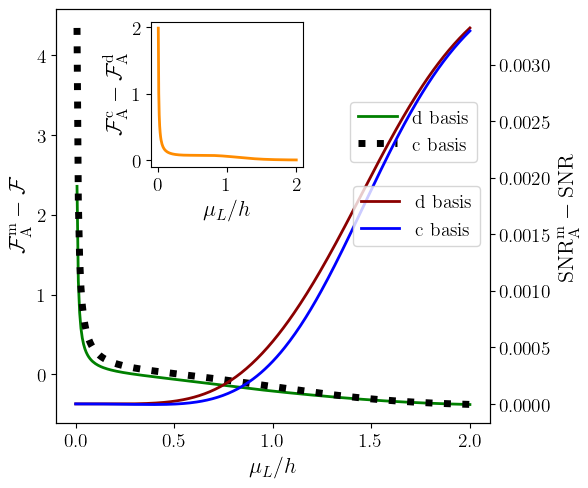

In [55]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

l0 = ax.plot(muL/eps, (FF_d-FF_LB),linewidth=2.0, color='g',linestyle='-', label=r'${\rm d}~\mathrm{basis}$')
l0 = ax.plot(muL/eps, (FF_c-FF_LB),linewidth=5.0, color='black',linestyle=':', label=r'${\rm c}~\mathrm{basis}$')

ax1 = ax.twinx()
l1 = ax1.plot(muL/eps, SNR_d - SNR_LB, linewidth=2.0, color='darkred',linestyle='-', label=r'${\rm d}~\mathrm{basis}$')
l1 = ax1.plot(muL/eps, SNR_c - SNR_LB, linewidth=2.0, color='b',linestyle='-', label=r'${\rm c}~\mathrm{basis}$')

# Create inset axes (zoom on lambda, e.g. g=0.8-1.2 region)
ax_inset = ax.inset_axes([0.22, 0.62, 0.35, 0.35])  # [x, y, width, height] in axes fraction
ax_inset.plot(muL[1:]/eps, (FF_c[1:]-FF_d[1:]), linewidth=2.0, color='darkorange',linestyle='-', label=r'${\rm d}~\mathrm{basis}$')
ax_inset.set(xlabel=r'$\mu_L/h$');
ax_inset.set(ylabel=r'$\mathcal{F}^{\rm c}_{\rm A} - \mathcal{F}^{\rm d}_{\rm A}$');
ax_inset.set_xticks(np.arange(0.0, 2.1, 1.0));

# ax.legend(loc='upper right');
ax.legend(loc='upper center', bbox_to_anchor=(0.825, 0.8));
ax1.legend(loc='center right');
ax.set(xlabel=r'$\mu_L/h$');

ax.set(ylabel=r'$\mathcal{F}^{\rm m}_{\rm A} - \mathcal{F}$');
ax1.set(ylabel=r'$\mathrm{SNR}^{\rm m}_{\rm A} - \mathrm{SNR}$');
plt.tight_layout(pad=.7, w_pad=.7, h_pad=.3);
#fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/snr_over_chemical_potentialV2.pdf', format='pdf')

QuTiP 5.2.0 | default atol = 1e-12

=== model (a): local/c basis ===
max Hermiticity defect of Choi matrix : 1.27e-14
most negative Choi eigenvalue          : -8.74e-02
      atol  CP fraction   points flipped vs default
     1e-16       0.0000                           0
     1e-15       0.0000                           0
     1e-14       0.0000                           0
     1e-13       0.0000                           0
     1e-12       0.0000                           0
     1e-11       0.0017                         165
     1e-10       0.0689                        6864
     1e-09       0.1595                       15894
     1e-08       0.2502                       24924
     1e-07       0.3408                       33954
     1e-06       0.4314                       42984
fragile points (verdict changes for atol in [1e-14,1e-10]): 6864 of 99631

=== model (b): d basis ===
max Hermiticity defect of Choi matrix : 1.14e-14
most negative Choi eigenvalue          : -3.46e-02
     

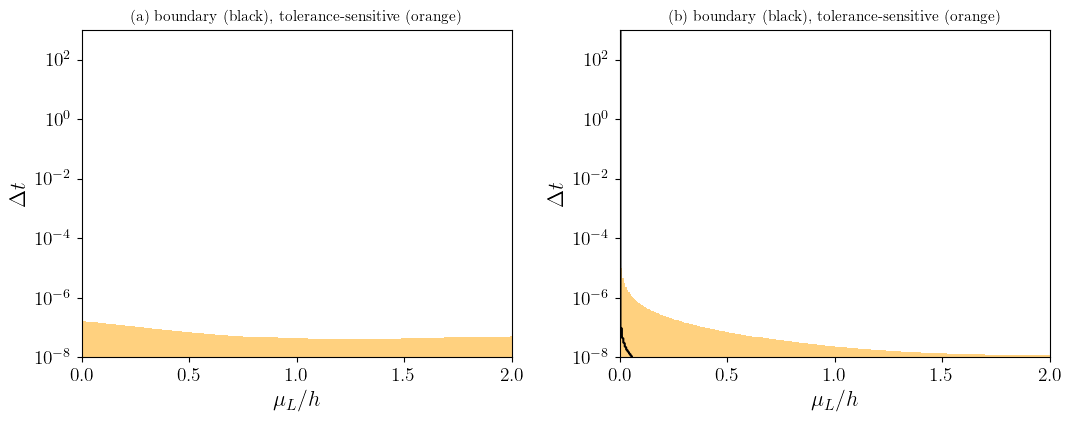

In [56]:
try:
    atol_default = qutip.settings.core['atol']      # QuTiP 5.x
except Exception:
    atol_default = qutip.settings.atol              # QuTiP 4.x
print("QuTiP", qutip.__version__, "| default atol =", atol_default)

atols = np.logspace(-16, -6, 11)

def sweep(choi_min, herm_def, label):
    ref = choi_min >= -atol_default                  # what iscp gives at default atol
    print(f"\n=== {label} ===")
    print(f"max Hermiticity defect of Choi matrix : {herm_def.max():.2e}")
    print(f"most negative Choi eigenvalue          : {choi_min.min():.2e}")
    print(f"{'atol':>10} {'CP fraction':>12} {'points flipped vs default':>27}")
    flips = []
    for a in atols:
        cp = choi_min >= -a
        n_flip = np.count_nonzero(cp != ref)
        flips.append(n_flip)
        print(f"{a:10.0e} {cp.mean():12.4f} {n_flip:27d}")
    # "fragile" points: CP verdict changes anywhere in atol in [1e-14, 1e-10]
    lo = choi_min >= -1e-14
    hi = choi_min >= -1e-10
    fragile = lo != hi
    print(f"fragile points (verdict changes for atol in [1e-14,1e-10]): "
          f"{np.count_nonzero(fragile)} of {fragile.size}")
    return np.array(flips), fragile

flips_l, fragile_l = sweep(choi_min_l, herm_def_l, "model (a): local/c basis")
flips_g, fragile_g = sweep(choi_min_g, herm_def_g, "model (b): d basis")

# Visual check: where in the (mu_L, Delta t) plane is the verdict tolerance-sensitive?
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, cm, fr, ttl in [(ax[0], choi_min_l, fragile_l, '(a)'),
                        (ax[1], choi_min_g, fragile_g, '(b)')]:
    # CP/non-CP boundary at default atol, plus the fragile region shaded
    a_.contourf(muL/eps, tau, fr.T.astype(float), levels=[0.5, 1.5], colors=['orange'], alpha=0.5)
    a_.contour(muL/eps, tau, (cm >= -atol_default).T.astype(float), levels=[0.5], colors='k')
    a_.set_yscale('log'); a_.set_xlabel(r'$\mu_L/h$'); a_.set_ylabel(r'$\Delta t$')
    a_.set_title(ttl + ' boundary (black), tolerance-sensitive (orange)', fontsize=11)
plt.tight_layout(); plt.show()